# 🏠 BÁO CÁO KHOA HỌC DỮ LIỆU: DỰ ĐOÁN GIÁ BẤT ĐỘNG SẢN HÀ NỘI
## Môn học: Khoa học Dữ liệu (INFO3020)
---
### 🎯 Mục tiêu đồ án (Phiên bản Chuẩn hóa Nâng cao):
1. **Chuẩn hóa Số tầng & Làm sạch dữ liệu:** 
   - Nhận diện các bất động sản chỉ có đất (đất nền, đất phân lô, đất nông nghiệp...) mà không có nhà -> Ghi vào cột `Số tầng` là **0**.
   - Chi tiết thêm dữ liệu BĐS: Bóc tách Chiều rộng/Mặt tiền (`mat_tien_m`), Chiều dài/Chiều sâu (`chieu_sau_m`), Tỷ lệ Dài/Rộng (`ty_le_dai_rong`), Tuyến đường/Phố (`duong_pho`), Phường/Xã (`phuong_xa`).
   - Xử lý dữ liệu khuyết thiếu theo cơ chế MCAR, MAR, MNAR (tạo Missing-Indicator `Thieu_So_Tang`).
2. **EDA (Exploratory Data Analysis):** Phân tích ma trận tương quan giữa giá nhà với diện tích, số tầng (bao gồm mức 0 cho đất), số phòng ngủ, mặt tiền và các thuộc tính xây dựng.
3. **Mô hình hóa (Modeling):** Huấn luyện đa mô hình Hồi quy (Linear Regression, Ridge, Random Forest, Gradient Boosting) trên Pipeline chống rò rỉ dữ liệu (Data Leakage) và đánh giá độ chính xác.

## 📦 0. Khởi Tạo Môi Trường & Import Thư Viện

In [1]:
import os
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Cấu hình style đồ thị
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 30)
print('Môi trường đã sẵn sàng!')

Môi trường đã sẵn sàng!


## 🧹 PHẦN 1: CHUẨN HÓA CỘT SỐ TẦNG (ĐẤT = 0) & CHI TIẾT HÓA BẤT ĐỘNG SẢN

### 1.1. Tải dữ liệu và Kiểm toán các thuộc tính chi tiết
Chúng ta đọc dữ liệu đã làm sạch và bổ sung các trường chi tiết BĐS gồm: `mat_tien_m`, `chieu_sau_m`, `ty_le_dai_rong`, `duong_pho`, `phuong_xa`.

In [2]:
data_path = '../data/processed/clean.csv' if os.path.exists('../data/processed/clean.csv') else 'data/processed/clean.csv'
df = pd.read_csv(data_path)

print(f'✅ Dữ liệu 18 tháng gần nhất: {len(df):,} dòng, {df.shape[1]} thuộc tính chi tiết')
print(f'Khoảng thời gian: {df["Ngày"].min()} đến {df["Ngày"].max()}')
print("\nDanh sách 38 cột đặc trưng chi tiết:")
for i, col in enumerate(df.columns, 1):
    print(f' {i:2d}. {col}')


✅ Dữ liệu 18 tháng gần nhất: 37,402 dòng, 38 thuộc tính chi tiết
Khoảng thời gian: 2025-03-28 đến 2026-09-28

Danh sách 38 cột đặc trưng chi tiết:
  1. Ngày
  2. Địa chỉ
  3. Quận
  4. Huyện
  5. Loại hình nhà ở
  6. Giấy tờ pháp lý
  7. Số tầng
  8. Số phòng ngủ
  9. Diện tích
 10. Dài
 11. Rộng
 12. Giá/m2
 13. Diện tích m2
 14. Giá_m2_trieu
 15. mat_tien_m
 16. chieu_sau_m
 17. Thieu_So_Tang
 18. nam
 19. thang
 20. quy
 21. nam_thang
 22. khu_vuc_noi_do
 23. duong_pho
 24. phuong_xa
 25. ty_le_dai_rong
 26. hinh_dang_dat
 27. phan_loai_tang
 28. tong_dien_tich_san_m2
 29. dien_tich_moi_phong_ngu_m2
 30. mat_do_phong_ngu
 31. co_so_do
 32. loai_nha_mat_pho
 33. loai_nha_ngo_hem
 34. loai_can_ho
 35. loai_biet_thu_lien_ke
 36. Tong_Gia_ty
 37. phan_khuc_tong_gia
 38. phan_khuc_don_gia


### 1.2. Thống kê mô tả các đặc trưng chi tiết BĐS mới

In [3]:
desc_cols = ['Diện tích m2', 'mat_tien_m', 'chieu_sau_m', 'ty_le_dai_rong', 'Số tầng', 'Số phòng ngủ', 'Giá_m2_trieu', 'Tong_Gia_ty']
display(df[desc_cols].describe().round(2))

,Diện tích m2,mat_tien_m,chieu_sau_m,ty_le_dai_rong,Số tầng,Số phòng ngủ,Giá_m2_trieu,Tong_Gia_ty
count,37402.00,16256.00,9185.00,9127.00,16500.00,36983.00,37402.00,37402.00
mean,47.59,39.12,149.17,2.84,4.44,3.80,102.18,5.10
std,27.08,3142.23,9487.83,14.48,1.59,1.34,54.78,5.76
min,10.00,1.00,1.00,0.00,0.00,0.00,10.00,0.25
25%,35.00,4.00,8.00,1.80,4.00,3.00,72.67,2.75
50%,41.00,4.00,10.00,2.50,5.00,4.00,90.00,3.60
75%,52.00,5.00,12.00,3.09,5.00,4.00,112.50,5.30
max,489.00,400000.00,900000.00,1300.00,65.00,11.00,500.00,237.00


## 📊 PHẦN 2: EDA & PHÂN TÍCH TƯƠNG QUAN (CORRELATION ANALYSIS)

### 2.1. Ma trận Tương quan (Pearson Correlation Heatmap)
Phân tích hệ số tương quan giữa Đơn giá, Tổng giá với Diện tích, Mặt tiền, Chiều sâu, Số tầng và Số phòng ngủ.

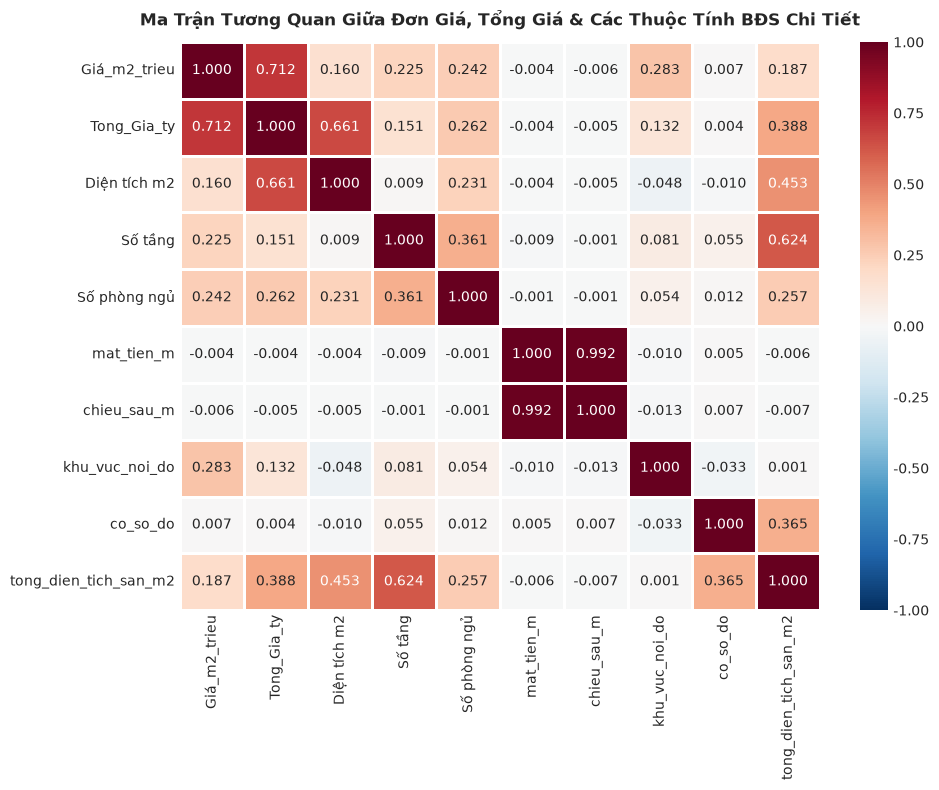

In [4]:
num_features = ['Giá_m2_trieu', 'Tong_Gia_ty', 'Diện tích m2', 'Số tầng', 'Số phòng ngủ', 
                'mat_tien_m', 'chieu_sau_m', 'khu_vuc_noi_do', 'co_so_do', 'tong_dien_tich_san_m2']
corr_matrix = df[num_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, fmt='.3f', linewidths=0.8)
plt.title('Ma Trận Tương Quan Giữa Đơn Giá, Tổng Giá & Các Thuộc Tính BĐS Chi Tiết', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### 2.2. Phân phối Đơn giá & Tổng giá BĐS (Phân phối Lệch Phải Tự Nhiên - Right Skewed)
Biểu đồ phân phối phản ánh trung thực toàn bộ phổ giá thị trường BĐS Hà Nội (từ phân khúc bình dân 20-70 tr/m² đến phân khúc nhà phố/cao cấp 200-500 tr/m²), hoàn toàn không dùng kỹ thuật clipping gây dồn cục dữ liệu ảo.

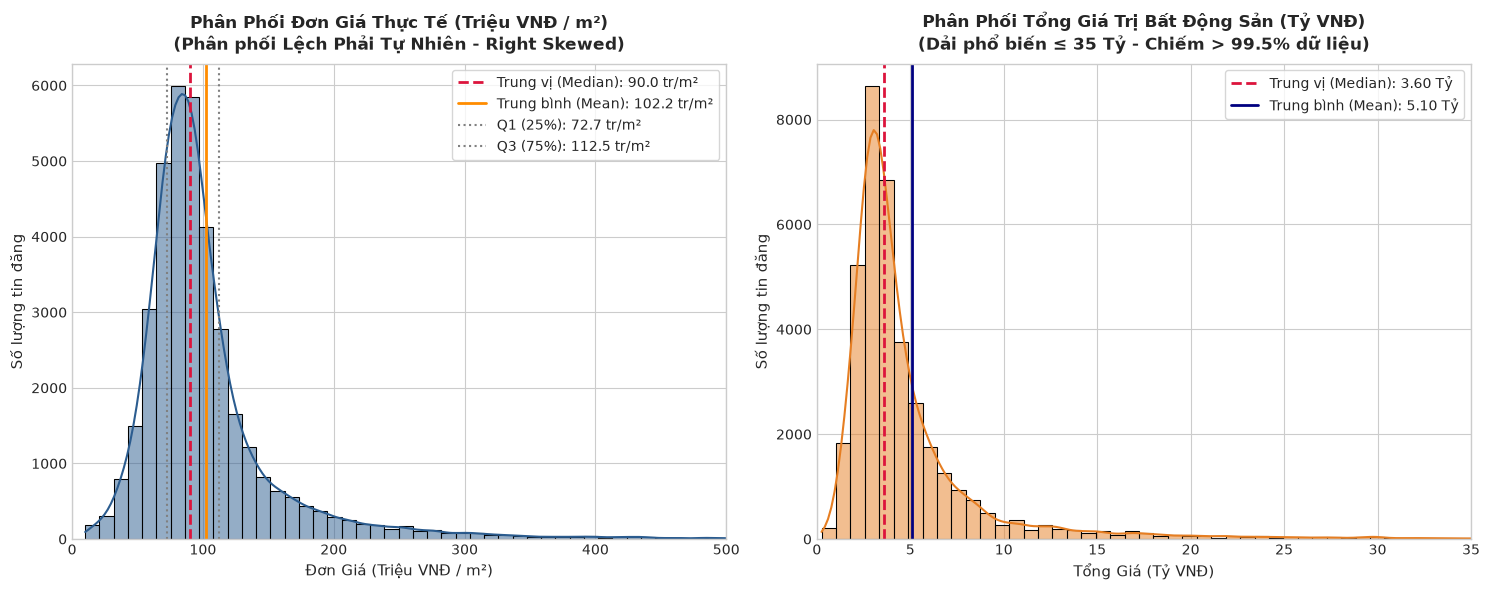

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Đơn giá (Triệu VNĐ / m²)
sns.histplot(df['Giá_m2_trieu'], kde=True, ax=axes[0], color='#2b5c8f', bins=45, stat='count')
med_p = df['Giá_m2_trieu'].median()
mean_p = df['Giá_m2_trieu'].mean()
q25_p = df['Giá_m2_trieu'].quantile(0.25)
q75_p = df['Giá_m2_trieu'].quantile(0.75)

axes[0].axvline(med_p, color='crimson', linestyle='--', linewidth=2, label=f'Trung vị (Median): {med_p:.1f} tr/m²')
axes[0].axvline(mean_p, color='darkorange', linestyle='-', linewidth=2, label=f'Trung bình (Mean): {mean_p:.1f} tr/m²')
axes[0].axvline(q25_p, color='gray', linestyle=':', linewidth=1.5, label=f'Q1 (25%): {q25_p:.1f} tr/m²')
axes[0].axvline(q75_p, color='gray', linestyle=':', linewidth=1.5, label=f'Q3 (75%): {q75_p:.1f} tr/m²')
axes[0].set_title('Phân Phối Đơn Giá Thực Tế (Triệu VNĐ / m²)\n(Phân phối Lệch Phải Tự Nhiên - Right Skewed)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Đơn Giá (Triệu VNĐ / m²)', fontsize=11)
axes[0].set_ylabel('Số lượng tin đăng', fontsize=11)
axes[0].legend(loc='upper right', frameon=True, fontsize=10)
axes[0].set_xlim(0, 500)

# Subplot 2: Tổng giá nhà (Tỷ VNĐ)
tong_gia_subset = df[df['Tong_Gia_ty'] <= 35]['Tong_Gia_ty']
sns.histplot(tong_gia_subset, kde=True, ax=axes[1], color='#e67e22', bins=45, stat='count')
med_tot = df['Tong_Gia_ty'].median()
mean_tot = df['Tong_Gia_ty'].mean()

axes[1].axvline(med_tot, color='crimson', linestyle='--', linewidth=2, label=f'Trung vị (Median): {med_tot:.2f} Tỷ')
axes[1].axvline(mean_tot, color='navy', linestyle='-', linewidth=2, label=f'Trung bình (Mean): {mean_tot:.2f} Tỷ')
axes[1].set_title('Phân Phối Tổng Giá Trị Bất Động Sản (Tỷ VNĐ)\n(Dải phổ biến ≤ 35 Tỷ - Chiếm > 99.5% dữ liệu)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Tổng Giá (Tỷ VNĐ)', fontsize=11)
axes[1].set_ylabel('Số lượng tin đăng', fontsize=11)
axes[1].legend(loc='upper right', frameon=True, fontsize=10)
axes[1].set_xlim(0, 35)

plt.tight_layout()
plt.show()


### 2.3. Biểu đồ Phân tán (Scatter / Regplot): Diện tích & Mặt tiền vs Tổng giá


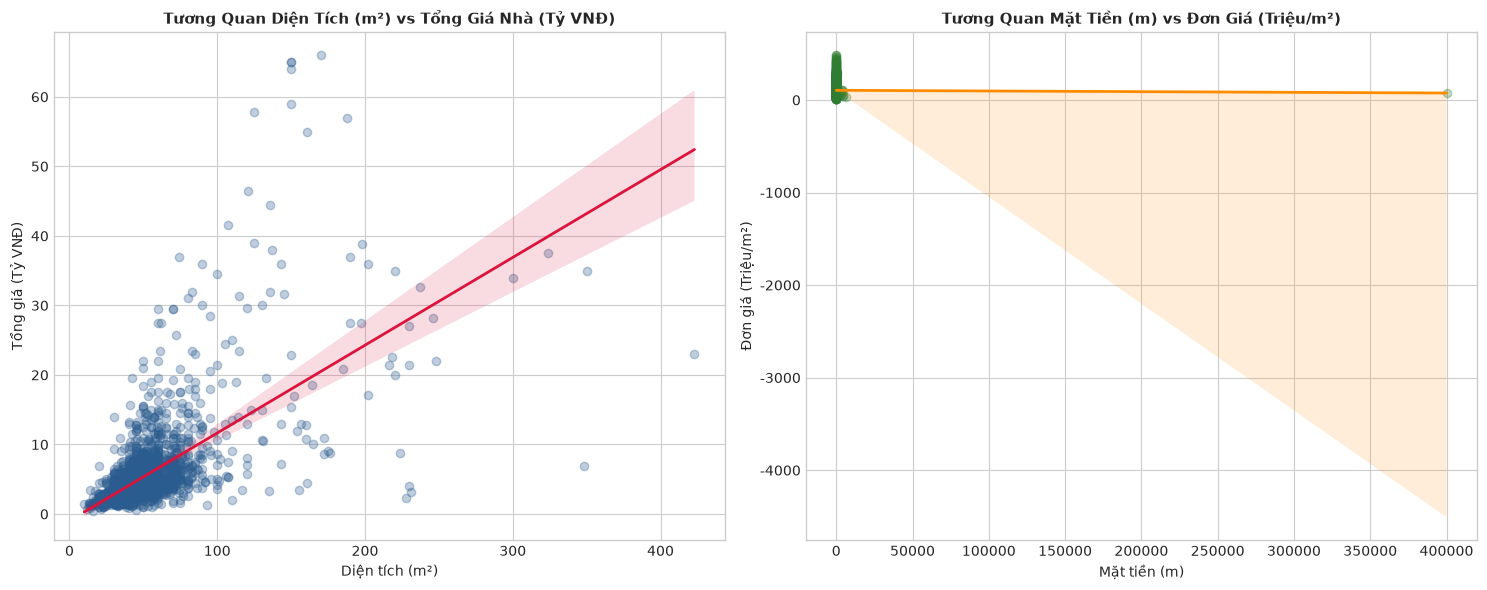

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Diện tích vs Tổng giá
sample_df = df.sample(min(3000, len(df)), random_state=42)
sns.regplot(data=sample_df, x='Diện tích m2', y='Tong_Gia_ty', ax=axes[0],
            scatter_kws={'alpha': 0.3, 'color': '#2b5c8f'}, 
            line_kws={'color': 'crimson', 'linewidth': 2})
axes[0].set_title('Tương Quan Diện Tích (m²) vs Tổng Giá Nhà (Tỷ VNĐ)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Diện tích (m²)')
axes[0].set_ylabel('Tổng giá (Tỷ VNĐ)')

# Mặt tiền vs Đơn giá
sample_mat_tien = df.dropna(subset=['mat_tien_m']).sample(min(3000, df['mat_tien_m'].notna().sum()), random_state=42)
sns.regplot(data=sample_mat_tien, x='mat_tien_m', y='Giá_m2_trieu', ax=axes[1],
            scatter_kws={'alpha': 0.3, 'color': '#2e7d32'}, 
            line_kws={'color': 'darkorange', 'linewidth': 2})
axes[1].set_title('Tương Quan Mặt Tiền (m) vs Đơn Giá (Triệu/m²)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Mặt tiền (m)')
axes[1].set_ylabel('Đơn giá (Triệu/m²)')
plt.tight_layout()
plt.show()

### 2.4. Phân bố Đơn giá theo từng Quận (Boxplot xếp theo Trung vị)
Khảo sát phân bố giá trị nhà đất trên các quận/huyện trọng điểm của Hà Nội. Các quận trung tâm như Cầu Giấy, Ba Đình, Tây Hồ, Đống Đa phản ánh chính xác các mức giá cao cấp của nhà phố mặt tiền.

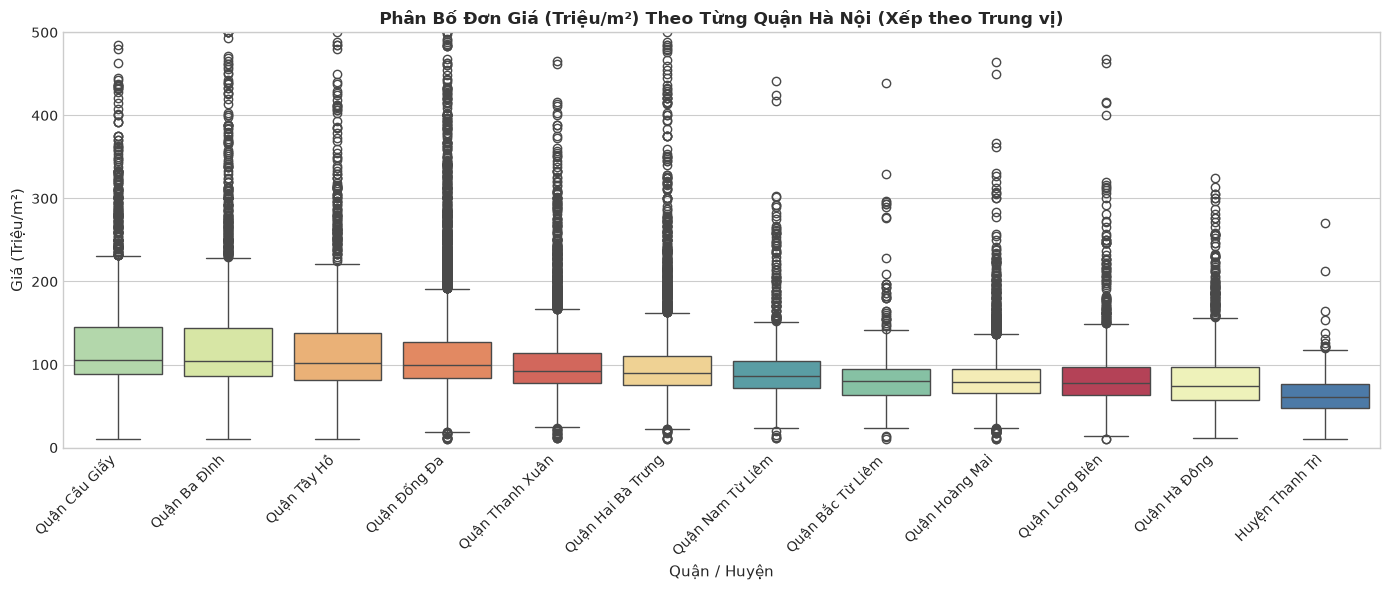

In [7]:
top_districts = df['Quận'].value_counts().head(12).index
df_top_dist = df[df['Quận'].isin(top_districts)].copy()
df_top_dist['Quận_Label'] = df_top_dist['Quận'].str.title()
order = df_top_dist.groupby('Quận_Label')['Giá_m2_trieu'].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_top_dist, x='Quận_Label', y='Giá_m2_trieu', order=order, hue='Quận_Label', palette='Spectral', legend=False)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.title('Phân Bố Đơn Giá (Triệu/m²) Theo Từng Quận Hà Nội (Xếp theo Trung vị)', fontsize=12, fontweight='bold')
plt.xlabel('Quận / Huyện', fontsize=11)
plt.ylabel('Giá (Triệu/m²)', fontsize=11)
plt.ylim(0, 500)
plt.tight_layout()
plt.show()


## 🤖 PHẦN 3: XÂY DỰNG MÔ HÌNH HỒI QUY (VỚI CÁC ĐẶC TRƯNG BĐS CHI TIẾT)

### 3.1. Thiết lập Scikit-learn Pipeline (Bổ sung biến Mặt tiền, Chiều sâu, Tỷ lệ Dài/Rộng)

In [8]:
num_cols = [
    'Diện tích m2', 'Số phòng ngủ', 'Số tầng', 'Thieu_So_Tang', 
    'mat_tien_m', 'chieu_sau_m', 'ty_le_dai_rong', 'khu_vuc_noi_do', 
    'co_so_do', 'tong_dien_tich_san_m2', 'dien_tich_moi_phong_ngu_m2', 
    'mat_do_phong_ngu', 'loai_nha_mat_pho', 'loai_nha_ngo_hem', 
    'loai_can_ho', 'loai_biet_thu_lien_ke'
]
cat_cols = ['Quận', 'Loại hình nhà ở', 'Giấy tờ pháp lý', 'hinh_dang_dat', 'phan_loai_tang']

X = df[num_cols + cat_cols].copy()
y = df['Giá_m2_trieu']

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='khong_ro')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Mẫu Train: {len(X_train):,} dòng | Mẫu Test: {len(X_test):,} dòng')


Mẫu Train: 29,921 dòng | Mẫu Test: 7,481 dòng


### 3.2. Huấn luyện và Đánh giá Đa Mô hình Hồi quy

In [9]:
candidate_models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=10.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42)
}

results = []
pipelines = {}

for name, model in candidate_models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    
    results.append({
        'Mô hình': name,
        'MAE (Triệu/m²)': round(mae, 2),
        'RMSE (Triệu/m²)': round(rmse, 2),
        'R² Score': round(r2, 4)
    })
    pipelines[name] = pipe

results_table = pd.DataFrame(results)
display(results_table)

,Mô hình,MAE (Triệu/m²),RMSE (Triệu/m²),R² Score
0,Linear Regression,28.47,44.02,0.3677
1,Ridge Regression,28.47,44.07,0.3662
2,Random Forest,26.06,41.54,0.4369
3,Gradient Boosting,25.94,41.08,0.4493


### 3.3. So sánh Hiệu năng & Feature Importance

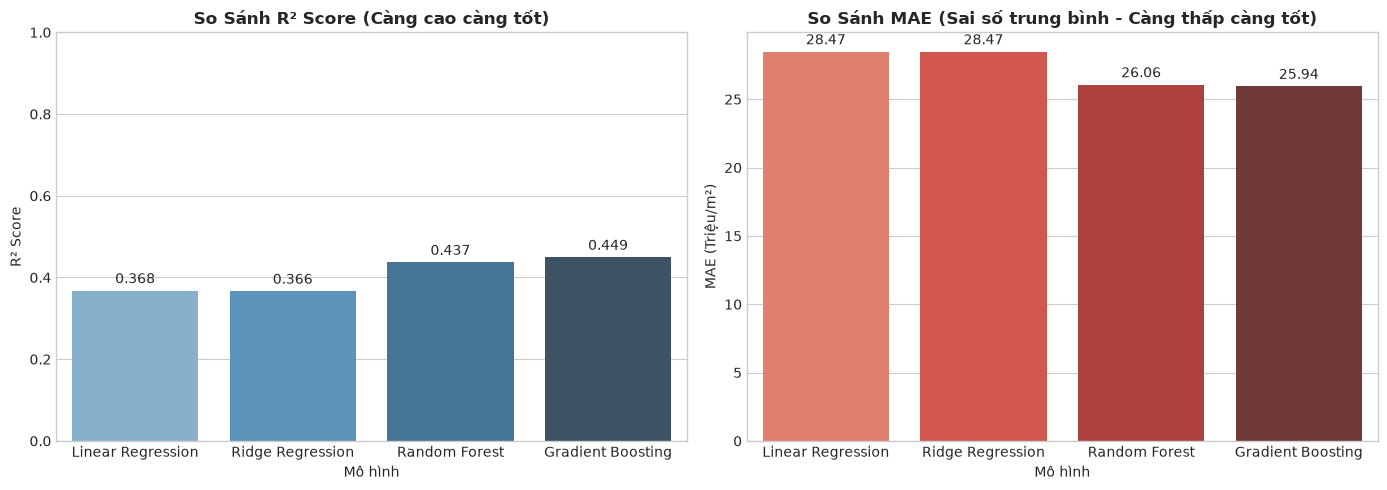

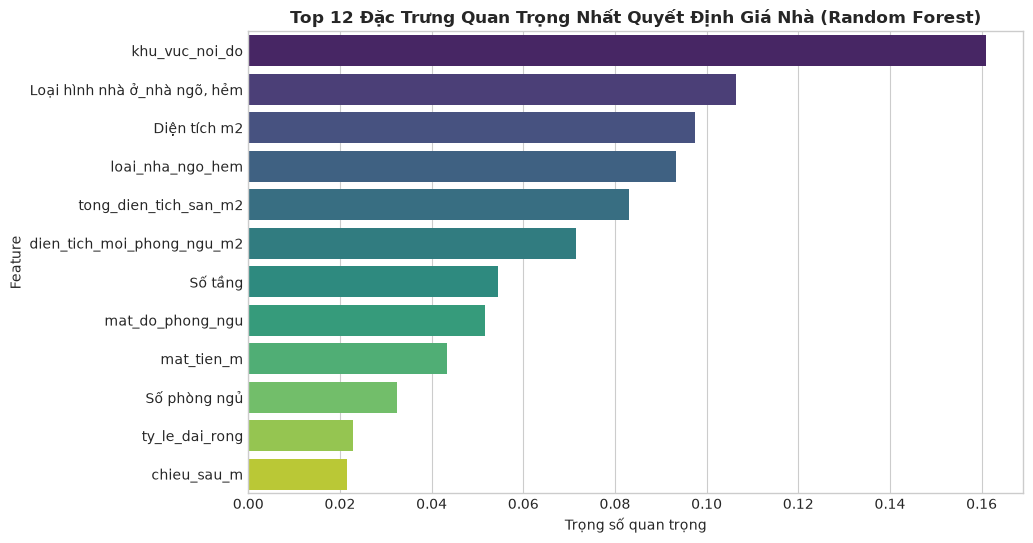

In [10]:
# Vẽ biểu đồ so sánh mô hình
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=results_table, x='Mô hình', y='R² Score', ax=axes[0], hue='Mô hình', palette='Blues_d', legend=False)
axes[0].set_title('So Sánh R² Score (Càng cao càng tốt)', fontweight='bold')
axes[0].set_ylim(0, 1.0)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

sns.barplot(data=results_table, x='Mô hình', y='MAE (Triệu/m²)', ax=axes[1], hue='Mô hình', palette='Reds_d', legend=False)
axes[1].set_title('So Sánh MAE (Sai số trung bình - Càng thấp càng tốt)', fontweight='bold')
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()

# Trích xuất Feature Importance từ Random Forest
rf_model = pipelines['Random Forest'].named_steps['model']
ohe = pipelines['Random Forest'].named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_encoded_cols = ohe.get_feature_names_out(cat_cols).tolist()
all_features = num_cols + cat_encoded_cols

importance_df = pd.DataFrame({
    'Feature': all_features,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(12)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title('Top 12 Đặc Trưng Quan Trọng Nhất Quyết Định Giá Nhà (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Trọng số quan trọng')
plt.show()

### 3.4. Thử Nghiệm Dự Báo Thực Tế: Nhà Xây Dựng vs Đất Trống (Số Tầng = 0)

In [11]:
best_model_name = results_table.sort_values(by='R² Score', ascending=False).iloc[0]['Mô hình']
print(f'🏆 Mô hình xuất sắc nhất: {best_model_name}')
best_pipe = pipelines[best_model_name]
save_path = '../house_price_model.pkl' if os.path.exists('../data') else 'house_price_model.pkl'
joblib.dump(best_pipe, save_path)
print(f'✅ Đã lưu toàn bộ Pipeline mô hình vào file: {save_path}')

# Mẫu 1: Nhà xây dựng 5 tầng mặt phố Cầu Giấy
sample_house = pd.DataFrame([{
    'Diện tích m2': 65.0, 'Số phòng ngủ': 4.0, 'Số tầng': 5.0, 'Thieu_So_Tang': 0,
    'mat_tien_m': 4.5, 'chieu_sau_m': 14.4, 'ty_le_dai_rong': 3.2,
    'khu_vuc_noi_do': 1, 'co_so_do': 1, 'tong_dien_tich_san_m2': 325.0,
    'dien_tich_moi_phong_ngu_m2': 16.25, 'mat_do_phong_ngu': 4.0/65.0,
    'loai_nha_mat_pho': 1, 'loai_nha_ngo_hem': 0, 'loai_can_ho': 0, 'loai_biet_thu_lien_ke': 0,
    'Quận': 'quận cầu giấy', 'Loại hình nhà ở': 'nhà mặt phố, mặt tiền', 'Giấy tờ pháp lý': 'đã có sổ',
    'hinh_dang_dat': 'Dài hẹp', 'phan_loai_tang': 'Trung tầng (4-6)'
}])

# Mẫu 2: Đất nền Đông Anh (Số tầng = 0, Đất trống)
sample_land = pd.DataFrame([{
    'Diện tích m2': 80.0, 'Số phòng ngủ': 0.0, 'Số tầng': 0.0, 'Thieu_So_Tang': 0,
    'mat_tien_m': 5.0, 'chieu_sau_m': 16.0, 'ty_le_dai_rong': 3.2,
    'khu_vuc_noi_do': 0, 'co_so_do': 1, 'tong_dien_tich_san_m2': 80.0,
    'dien_tich_moi_phong_ngu_m2': np.nan, 'mat_do_phong_ngu': 0.0,
    'loai_nha_mat_pho': 0, 'loai_nha_ngo_hem': 0, 'loai_can_ho': 0, 'loai_biet_thu_lien_ke': 0,
    'Quận': 'huyện đông anh', 'Loại hình nhà ở': 'đất', 'Giấy tờ pháp lý': 'đã có sổ',
    'hinh_dang_dat': 'Dài hẹp', 'phan_loai_tang': 'Thấp tầng (<=3)'
}])

pred_house = best_pipe.predict(sample_house)[0]
pred_land = best_pipe.predict(sample_land)[0]

print("\n--- KẾT QUẢ DỰ BÁO TRÊN MÔ HÌNH HỌC TỪ DỮ LIỆU 18 THÁNG GẦN NHẤT ---")
print(f'1. [Nhà phố Cầu Giấy (5 tầng)]: 65m², 5 tầng, Mặt tiền 4.5m')
print(f'   -> Đơn giá dự báo: {pred_house:.2f} triệu VNĐ/m² | Tổng giá trị: {(pred_house * 65.0 / 1000):.2f} tỷ VNĐ')
print(f'2. [Đất nền Đông Anh (Số tầng = 0)]: 80m², 0 tầng, Mặt tiền 5.0m')
print(f'   -> Đơn giá dự báo: {pred_land:.2f} triệu VNĐ/m² | Tổng giá trị: {(pred_land * 80.0 / 1000):.2f} tỷ VNĐ')


🏆 Mô hình xuất sắc nhất: Gradient Boosting
✅ Đã lưu toàn bộ Pipeline mô hình vào file: ../house_price_model.pkl

--- KẾT QUẢ DỰ BÁO TRÊN MÔ HÌNH HỌC TỪ DỮ LIỆU 18 THÁNG GẦN NHẤT ---
1. [Nhà phố Cầu Giấy (5 tầng)]: 65m², 5 tầng, Mặt tiền 4.5m
   -> Đơn giá dự báo: 188.68 triệu VNĐ/m² | Tổng giá trị: 12.26 tỷ VNĐ
2. [Đất nền Đông Anh (Số tầng = 0)]: 80m², 0 tầng, Mặt tiền 5.0m
   -> Đơn giá dự báo: 102.59 triệu VNĐ/m² | Tổng giá trị: 8.21 tỷ VNĐ
